# Datos científicos con Pandas y PostgreSQL
## Tres clases magistrales de 90 minutos

**Clase 1:** Pandas en Colab (90 min). **Clase 2:** Pandas (45 min) y SQL en PostgreSQL (45 min). **Clase 3:** SQL, archivos y terminal Bash (90 min).

Leemos un CSV científico público, interpretamos ausencias y grupos, y aprendemos a expresar preguntas sobre esos datos con SQL. Cada bloque combina explicación, código y una interpretación. Ejecuta Pandas en orden; lee los bloques SQL aquí y ejecútalos en `psql`, dentro de la terminal de VS Code conectada a Ubuntu WSL2.

Prepara WSL2, Ubuntu, VS Code y PostgreSQL **antes de la segunda clase**, siguiendo `GUIA_POSTGRESQL.md`. La instalación no forma parte de los 270 minutos de clase. PostgreSQL es el servidor; VS Code es el editor; psql es el cliente. No se requiere conexión entre Colab y PostgreSQL. La integración con Python se demuestra mediante scripts locales y se profundiza fuera de clase.

Los ejercicios sin nota están en `02_practica_sin_nota.ipynb`. Son trabajo autónomo posterior. Los datos y preguntas no resuelven modelos, convolución, FFT ni validaciones del trabajo final.


In [1]:
from pathlib import Path
from io import BytesIO
import os, sys, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 12)
print('Python:', sys.version.split()[0], '| Pandas:', pd.__version__)


Python: 3.12.14 | Pandas: 3.0.1


### Fuente y diccionario
Usamos **Palmer Penguins**, observaciones recogidas por Kristen Gorman y Palmer Station LTER y distribuidas
por palmerpenguins. La copia de referencia tiene 344 registros, faltantes reales y grupos de tamaños distintos.
[Contexto científico](https://allisonhorst.github.io/palmerpenguins/) ·
[CSV](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv).

| Variable | Significado |
|---|---|
| species, island | Especie e isla |
| bill_length_mm, bill_depth_mm | Longitud y altura del pico, mm |
| flipper_length_mm | Longitud de aleta, mm |
| body_mass_g | Masa corporal, g |
| sex, year | Sexo registrado y año |

Una fila es un registro de observación, no una muestra de una señal temporal uniforme.
El identificador que agregaremos identifica filas de esta copia, no animales seguidos a lo largo del tiempo.
El material se distribuye bajo CC0; citamos igualmente su procedencia. La carpeta datos incluye la fuente y huella de la copia.

In [2]:
URL_CSV = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
datos_originales = pd.read_csv(URL_CSV, na_values=['NA'])
print('Filas y columnas:', datos_originales.shape)
display(datos_originales.head())
# Alternativa offline, tras subir el CSV incluido:
# datos_originales = pd.read_csv('penguins.csv', na_values=['NA'])
# En Jupyter local, leer desde el PC:
# datos_originales = pd.read_csv(r'C:/ruta/penguins.csv', na_values=['NA'])


Filas y columnas: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


---
# Clase 1 · Análisis completo con Pandas · 90 min

| Minutos | Bloque |
|---|---|
| 0–15 | Fuentes web, Drive y PC |
| 15–30 | Estructuras, tipos e índices |
| 30–45 | Selección, orden y cálculo vectorizado |
| 45–60 | Faltantes y decisiones de transformación |
| 60–80 | Grupos, conteos y comparación |
| 80–90 | Figura e interpretación |

## 1.1 · CSV desde internet, Drive y PC · 0–15 min
`read_csv` necesita el contenido CSV, no una página de presentación. En GitHub usamos `raw`.
Una ficha de Kaggle no es una URL directa de CSV. Revisa `sep`, `decimal`, `encoding` y `na_values`:
un archivo separado por punto y coma puede parecer una sola columna si se lee con el separador equivocado.

### Google Drive
Descomenta este bloque si deseas usar Drive. El montaje solicita autorización y permite leer y escribir archivos.
`/content` es temporal; `/content/drive/MyDrive` corresponde al Drive montado. Guardar el notebook no guarda
automáticamente los archivos de la máquina. Conserva datos y resultados en una carpeta de la práctica.

In [3]:
# from google.colab import drive
# drive.mount('/content/drive')
# carpeta_drive = Path('/content/drive/MyDrive/Programacion/datos_cientificos')
# carpeta_drive.mkdir(parents=True, exist_ok=True)
# datos_originales.to_csv(carpeta_drive / 'penguins.csv', index=False)
# desde_drive = pd.read_csv(carpeta_drive / 'penguins.csv', na_values=['NA'])

# Leer desde el PC en Colab (abre un selector):
# from google.colab import files; subidos = files.upload()
# desde_pc = pd.read_csv(BytesIO(subidos['penguins.csv']), na_values=['NA'])


### Kaggle como fuente alternativa
El cliente oficial `kagglehub` descarga un dataset y devuelve una ruta local. A partir de ella usamos Pandas.
Algunos conjuntos requieren consentimiento o autenticación; en ese caso usa `kagglehub.login()` o secretos
de Colab. No escribas tokens en celdas compartidas. Este ejemplo es opcional: el análisis principal usa la fuente original.

El espejo de Kaggle puede tener otras columnas, por ejemplo `culmen_length_mm`, o no incluir el año.
Inspecciona el diccionario y adapta nombres antes de usarlo; no sustituyas silenciosamente el conjunto de clase.

In [4]:
# %pip install -q kagglehub
# import kagglehub
# ruta_kaggle = Path(kagglehub.dataset_download(
#     'parulpandey/palmer-archipelago-antarctica-penguin-data'))
# archivos_csv = sorted(ruta_kaggle.rglob('*.csv'))
# print(archivos_csv)  # Revisa qué archivos contiene antes de elegir.
# ejemplo_kaggle = pd.read_csv(archivos_csv[0])
# display(ejemplo_kaggle.head())


## 1.2 · Estructura y diagnóstico · 15–30 min
Un DataFrame combina columnas de tipos diferentes. Una columna es una Series con índice.
`shape` informa dimensiones, `info()` resume tipos y cobertura y `describe()` explora variables numéricas.
El tipo no sustituye el significado: un identificador numérico no adquiere sentido físico por calcular su media.

In [5]:
print(datos_originales.shape)
datos_originales.info()
display(datos_originales.isna().sum().rename('faltantes'))
display(datos_originales.describe().round(2))
print(type(datos_originales['body_mass_g']).__name__)
print(type(datos_originales[['body_mass_g']]).__name__)
display(datos_originales.loc[0:2, ['species','body_mass_g']])  # Incluye etiqueta 2.
display(datos_originales.iloc[0:2, [0,5]])                    # Excluye posición 2.


(344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
Name: faltantes, dtype: int64

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.00,342.00,342.00,342.00,344.00
mean,43.92,17.15,200.92,4201.75,2008.03
std,5.46,1.97,14.06,801.95,0.82
min,32.10,13.10,172.00,2700.00,2007.00
25%,39.22,15.60,190.00,3550.00,2007.00
50%,44.45,17.30,197.00,4050.00,2008.00
75%,48.50,18.70,213.00,4750.00,2009.00
max,59.60,21.50,231.00,6300.00,2009.00


Series
DataFrame


,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0


,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0


En la copia de referencia hay dos faltantes en cada medida y once en sexo. No hay que eliminar once filas
para cualquier pregunta: una masa sin sexo sigue siendo útil para describir masa por especie.
`.loc` selecciona etiquetas y `.iloc` posiciones. Ordenar cambia posiciones, no la identidad original de la fila.
Pandas alinea Series por etiqueta; NumPy opera por posición. Comprueba este contraste una vez:

In [6]:
a = pd.Series([10,20], index=['A','B'])
b = pd.Series([2,1], index=['B','A'])
print('Etiquetas:', (a+b).to_dict())
print('Posiciones:', a.to_numpy()+b.to_numpy())


Etiquetas: {'A': 11, 'B': 22}
Posiciones: [12 21]


Obtenemos A=11, B=22 frente a 12,21. Convertir a NumPy elimina etiquetas; exige comprobar el orden.

## 1.3 · Seleccionar y derivar columnas · 30–45 min
Renombramos columnas para hacer legibles las consultas. Trabajamos con una copia, agregamos identificador de fila
y convertimos g a kg mediante una operación vectorizada. No hacen falta un ciclo ni `apply`.

In [7]:
def preparar_tabla(original):
    tabla = original.copy()
    # Es una clave de fila de ESTA copia, no un identificador biológico del animal.
    tabla.insert(0, 'registro_id', np.arange(1, len(tabla) + 1))
    tabla = tabla.rename(columns={
        'species':'especie', 'island':'isla', 'sex':'sexo', 'year':'anio',
        'bill_length_mm':'pico_largo_mm', 'bill_depth_mm':'pico_alto_mm',
        'flipper_length_mm':'aleta_mm', 'body_mass_g':'masa_g'})
    tabla['sexo'] = tabla['sexo'].astype('string').str.strip().str.lower()
    tabla['masa_kg'] = tabla['masa_g'] / 1000.0
    return tabla
datos = preparar_tabla(datos_originales)


In [8]:
mascara = datos['especie'].eq('Adelie') & datos['masa_g'].ge(4000)
seleccion = (datos.loc[mascara, ['registro_id','especie','isla','masa_kg']]
                 .sort_values(['masa_kg','registro_id'], ascending=[False,True]))
display(seleccion.head(8))
print('Registros seleccionados:', len(seleccion))
datos['masa_disponible'] = datos['masa_g'].notna()
assert np.isclose(datos.loc[0,'masa_kg'], 3.750)


,registro_id,especie,isla,masa_kg
109,110,Adelie,Biscoe,4.775
101,102,Adelie,Biscoe,4.725
81,82,Adelie,Torgersen,4.700
7,8,Adelie,Torgersen,4.675
39,40,Adelie,Dream,4.650
45,46,Adelie,Dream,4.600
111,112,Adelie,Biscoe,4.600
17,18,Adelie,Torgersen,4.500


Registros seleccionados: 39


Para combinar comparaciones escritas con operadores, usa paréntesis y `&` o `|`, no `and`/`or`.
Para asignar por condición usa `datos.loc[mascara, 'columna'] = valor`; evita asignaciones encadenadas
como `datos[mascara]['columna'] = valor`. Predice qué filas se excluyen si cambias >=4000 por >4000.

## 1.4 · Limpiar según la pregunta · 45–60 min
No introducimos errores ficticios en el conjunto real. Primero auditamos la fuente.
Conservamos todas las filas y creamos vistas de análisis según qué medidas se necesitan.

In [9]:
print('Duplicados exactos:', datos_originales.duplicated().sum())
display(datos.loc[datos['masa_g'].isna(), ['registro_id','especie','isla','sexo','anio']])
para_masas = datos.dropna(subset=['masa_g']).copy()
assert len(para_masas) + datos['masa_g'].isna().sum() == len(datos)
assert datos['registro_id'].is_unique
print('Masas disponibles:', len(para_masas))


Duplicados exactos: 0


,registro_id,especie,isla,sexo,anio
3,4,Adelie,Torgersen,<NA>,2007
271,272,Gentoo,Biscoe,<NA>,2009


Masas disponibles: 342


La tabla simplificada no aporta una clave biológica original. Una coincidencia de medidas no demostraría
por sí sola duplicación de individuos; no eliminamos automáticamente supuestos duplicados.
Para estudiar masas usamos 342 registros de esta copia. No rellenamos los ausentes con cero o con la media:
eso alteraría la distribución y podría modificar asociaciones con otras variables.

La Serie siguiente es **artificial** y solo demuestra una conversión: `coerce` convierte texto no interpretable
en faltante. Para distinguir una ausencia original de un fallo hay que conservar el texto original.

In [10]:
texto = pd.Series(['3.5', None, 'error', '4.2'], dtype='string')
numero = pd.to_numeric(texto, errors='coerce')
display(pd.DataFrame({'original':texto, 'numero':numero,
                     'fallo_conversion':texto.notna() & numero.isna()}))


,original,numero,fallo_conversion
0,3.5,3.5,False
1,<NA>,<NA>,False
2,error,<NA>,True
3,4.2,4.2,False


## 1.5 · Resumir e interpretar · 60–80 min
`groupby` define grupos y `agg` sus reducciones. `size` cuenta filas y `count` valores presentes.
La desviación estándar de Pandas usa `ddof=1`: describe variación muestral, no incertidumbre instrumental.
Con una sola medida no hay estimación de dispersión muestral.

In [11]:
resumen = datos.groupby('especie', as_index=False).agg(
    registros=('registro_id','size'), masas_presentes=('masa_g','count'),
    masa_media_g=('masa_g','mean'), dispersion_g=('masa_g','std'),
    masa_min_g=('masa_g','min'), masa_max_g=('masa_g','max'))
resumen['cobertura_masa'] = resumen['masas_presentes']/resumen['registros']
display(resumen.round(3))
display(datos.groupby(['especie','sexo'], dropna=False)['masa_g'].agg(['count','mean']).round(2))


,especie,registros,masas_presentes,masa_media_g,dispersion_g,masa_min_g,masa_max_g,cobertura_masa
0,Adelie,152,151,3700.662,458.566,2850.0,4775.0,0.993
1,Chinstrap,68,68,3733.088,384.335,2700.0,4800.0,1.000
2,Gentoo,124,123,5076.016,504.116,3950.0,6300.0,0.992


count     mean
especie   sexo                  
Adelie    female     73  3368.84
          male       73  4043.49
          <NA>        5  3540.00
Chinstrap female     34  3527.21
          male       34  3938.97
Gentoo    female     58  4679.74
          male       61  5484.84
          <NA>        4  4587.50

`dropna=False` conserva el grupo con sexo ausente. Sin él desaparecería de ese agrupamiento.
Las medias por especie y por sexo responden preguntas diferentes; la composición de los grupos importa.
Una media de medias tampoco es siempre la media de los individuos: los tamaños de muestra son distintos.

In [12]:
media_individuos = datos['masa_g'].mean()
media_especies = resumen['masa_media_g'].mean()
media_ponderada = np.average(resumen['masa_media_g'], weights=resumen['masas_presentes'])
display(pd.Series({'por_individuos_g':media_individuos,
                   'media_de_medias_g':media_especies,
                   'media_ponderada_g':media_ponderada}).round(3))
assert np.isclose(media_individuos, media_ponderada)


por_individuos_g     4201.754
media_de_medias_g    4169.922
media_ponderada_g    4201.754
dtype: float64

## 1.6 · Figura con unidades · 80–90 min
Cada punto corresponde a dos medidas del mismo registro. Retomamos Matplotlib orientado a objetos:
figura, eje, leyenda y unidades. No ajustamos un modelo ni inferimos causalidad de la nube de puntos.

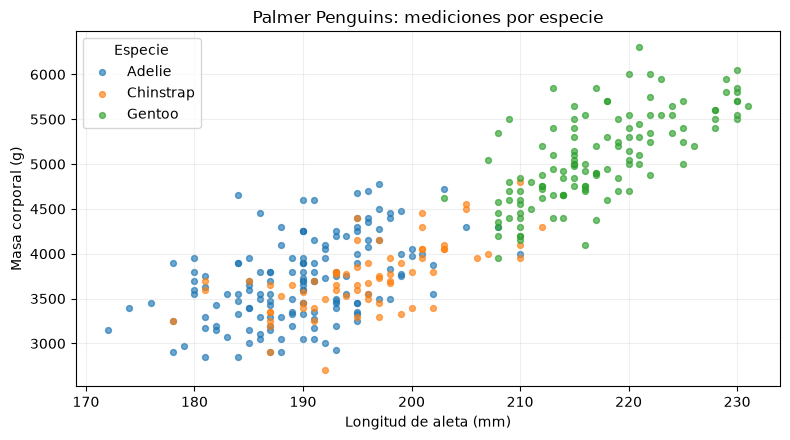

In [13]:
fig, ax = plt.subplots(figsize=(8,4.5))
for especie, grupo in datos.dropna(subset=['aleta_mm','masa_g']).groupby('especie'):
    ax.scatter(grupo['aleta_mm'], grupo['masa_g'], s=18, alpha=0.65, label=especie)
ax.set(xlabel='Longitud de aleta (mm)', ylabel='Masa corporal (g)',
       title='Palmer Penguins: mediciones por especie')
ax.legend(title='Especie'); ax.grid(alpha=0.2); fig.tight_layout(); plt.show()


Podemos describir distribuciones observadas y variabilidad dentro de grupos. Una asociación global puede
reflejar diferencias entre especies: no demuestra un mecanismo causal. Informa cobertura y procedencia.
Después de la clase: P1–P4 sin nota. Lee selección y faltantes en la documentación de Pandas.

---
# Clase 2 · De Pandas a PostgreSQL · 90 min
Primera mitad: completar Pandas. Segunda mitad: crear e interrogar una base propia.
Si reanudaste el entorno, ejecuta importaciones, lectura y la celda que define y llama `preparar_tabla`.

| Minutos | Bloque |
|---|---|
| 0–15 | merge y transform |
| 15–30 | pivot, melt y concat |
| 30–45 | Exportación, procedencia y comprobación |
| 45–55 | Servidor, base, esquema y tabla |
| 55–75 | Crear tablas y cargar datos |
| 75–90 | SELECT, WHERE, ORDER BY y NULL |

## 2.1 · Relacionar por claves · 0–15 min
Comparamos cada masa con la media de su especie. La tabla de medias es un resultado derivado, no metadatos
científicos inventados. La relación desde observaciones hacia medias por especie es muchos-a-uno.
`validate` detecta claves duplicadas e `indicator` permite revisar filas sin correspondencia.

In [14]:
datos = preparar_tabla(datos_originales)
medias = datos.groupby('especie', as_index=False).agg(media_especie_g=('masa_g','mean'))
anotada = datos.merge(medias, on='especie', how='left', validate='many_to_one', indicator=True)
anotada['desviacion_media_g'] = anotada['masa_g']-anotada['media_especie_g']
assert len(anotada) == len(datos)
assert anotada['_merge'].eq('both').all()
display(anotada[['registro_id','especie','masa_g','media_especie_g','desviacion_media_g']].head())
media_alineada = datos.groupby('especie')['masa_g'].transform('mean')
np.testing.assert_allclose(media_alineada, anotada['media_especie_g'])


,registro_id,especie,masa_g,media_especie_g,desviacion_media_g
0,1,Adelie,3750.0,3700.662252,49.337748
1,2,Adelie,3800.0,3700.662252,99.337748
2,3,Adelie,3250.0,3700.662252,-450.662252
3,4,Adelie,NaN,3700.662252,NaN
4,5,Adelie,3450.0,3700.662252,-250.662252


`transform` devuelve un resultado de grupo alineado con las filas originales. `merge` relaciona dos tablas
por claves. Elige la operación que exprese mejor la tarea.
Pandas puede emparejar claves nulas entre sí; la igualdad SQL con NULL no lo hace. Aquí especie no tiene faltantes.
Comprobamos un defecto deliberado sobre una copia: nunca se usa ese resultado para el análisis.

In [15]:
medias_defectuosas = pd.concat([medias, medias.iloc[[0]]], ignore_index=True)
try:
    datos.merge(medias_defectuosas, on='especie', validate='many_to_one')
except pd.errors.MergeError:
    print('Clave repetida detectada; unión defectuosa rechazada.')
else:
    raise AssertionError('Debía detectarse el defecto')


Clave repetida detectada; unión defectuosa rechazada.


## 2.2 · Formato largo y ancho · 15–30 min
Hay múltiples observaciones por especie y año. Un `pivot` directo de individuos tendría claves repetidas.
Primero resumimos, luego cambiamos de forma. `pivot_table` podría unir los pasos, pero exige elegir y justificar
un agregado. `melt` vuelve a una representación larga de los resúmenes, no recupera los individuos originales.

In [16]:
por_anio = datos.groupby(['especie','anio'], as_index=False).agg(
    media_g=('masa_g','mean'), n=('masa_g','count'))
ancha = por_anio.pivot(index='especie', columns='anio', values='media_g')
larga = ancha.reset_index().melt(id_vars='especie', var_name='anio', value_name='media_g')
display(por_anio.round(1))
display(ancha.round(1))
display(larga.head())


,especie,anio,media_g,n
0,Adelie,2007,3696.4,49
1,Adelie,2008,3742.0,50
2,Adelie,2009,3664.9,52
3,Chinstrap,2007,3694.2,26
4,Chinstrap,2008,3800.0,18
5,Chinstrap,2009,3725.0,24
6,Gentoo,2007,5070.6,34
7,Gentoo,2008,5019.6,46
8,Gentoo,2009,5140.7,43


anio,2007,2008,2009
especie,,,
Adelie,3696.4,3742.0,3664.9
Chinstrap,3694.2,3800.0,3725.0
Gentoo,5070.6,5019.6,5140.7


,especie,anio,media_g
0,Adelie,2007,3696.428571
1,Chinstrap,2007,3694.230769
2,Gentoo,2007,5070.588235
3,Adelie,2008,3742.000000
4,Chinstrap,2008,3800.000000


La tabla ancha contiene medias; perdió el detalle individual. Conservamos la tabla original para regresar a él.
`concat` apila lotes compatibles: no relaciona filas por claves ni elimina repeticiones.
Reunimos lotes de años distintos y comprobamos que recuperamos el original ordenado por su identificador.

In [17]:
lotes = [datos.loc[datos['anio'].eq(anio)] for anio in sorted(datos['anio'].unique())]
reunidos = pd.concat(lotes, ignore_index=True).sort_values('registro_id').reset_index(drop=True)
pd.testing.assert_frame_equal(reunidos, datos.reset_index(drop=True))
print('Lotes reunidos sin pérdida ni duplicación.')


Lotes reunidos sin pérdida ni duplicación.


## 2.3 · Exportar y conservar procedencia · 30–45 min
Guardamos datos, resumen y reglas. Un CSV no conserva por sí solo todos los tipos o decisiones de limpieza.
La huella SHA-256 permite detectar un cambio de bytes, pero no demuestra calidad científica.
La calcularemos sobre una **reexportación con Pandas**: sus bytes no tienen por qué coincidir con los del CSV original.

In [18]:
salidas = Path('salidas_curso'); salidas.mkdir(exist_ok=True)
datos_originales.to_csv(salidas/'penguins_reexportado.csv', index=False)
por_anio.to_csv(salidas/'resumen_especie_anio.csv', index=False)
procedencia = {'fuente':URL_CSV, 'filas':len(datos_originales), 'pandas':pd.__version__,
    'tipo_copia':'reexportación Pandas',
    'sha256':hashlib.sha256((salidas/'penguins_reexportado.csv').read_bytes()).hexdigest(),
    'regla':'medias con masa disponible, sin imputación'}
(salidas/'procedencia.json').write_text(json.dumps(procedencia,indent=2,ensure_ascii=False),encoding='utf-8')
assert np.isclose(datos_originales.loc[0,'body_mass_g']/1000, 3.75)
assert datos['masa_g'].count() == datos_originales['body_mass_g'].count()
print('Exportación lista en salidas_curso/')
# Tras montar Drive y definir carpeta_drive:
# por_anio.to_csv(carpeta_drive / 'resumen_especie_anio.csv', index=False)
# recuperado = pd.read_csv(carpeta_drive / 'resumen_especie_anio.csv')


Exportación lista en salidas_curso/


La ejecución desde un kernel limpio comprueba dependencias Python. Los resultados guardados no demuestran
que el código actual se pueda repetir. Aquí cerramos los 135 minutos de Pandas: lectura, selección,
transformación, grupos, relaciones, formatos, visualización y exportación.

## 2.4 · SQL puro en PostgreSQL · 45–55 min
SQL es el lenguaje; PostgreSQL es el servidor; psql en la terminal de VS Code (WSL), pgAdmin y VS Code son interfaces cliente.
Un editor no reemplaza al servidor. Pandas es una biblioteca Python y Psycopg es un cliente de PostgreSQL.

Para esta clase abre la carpeta del material en VS Code conectado a Ubuntu WSL2. En su terminal Bash ejecuta `psql -X -d curso_datos`. Verifica el prompt `curso_datos=>`.
La guía de preparación describe cómo hacerlo y qué guardar. No necesitamos las funciones de IA del editor.
Los archivos `.sql` se ejecutan con `psql -f` o se copian al prompt de psql.

Mantén este notebook como explicación y cambia al editor para ejecutar SQL. Cada bloque trae una pregunta,
la consulta y una interpretación. Usaremos nombres completos `curso_penguins.tabla` para evitar depender
de la sesión del editor o de un search_path guardado.

**Reconocer la conexión · ejecutar en el editor PostgreSQL**

```sql
SELECT version(), current_database(), current_user;
```

## 2.5 · Crear una base de trabajo con datos reales · 55–75 min
La guía de preparación crea la base local `curso_datos`. Dentro de ella crearemos el esquema
`curso_penguins`, el catálogo de especies y las observaciones. No hace falta permiso de administrador
para el ejercicio si tu usuario puede crear su propio esquema.

Abre `sql/00_crear_y_cargar.sql`, ejecútalo desde Bash con `psql -X -v ON_ERROR_STOP=1 -d curso_datos -f sql/00_crear_y_cargar.sql` **una sola vez**.
Es una carga reproducible de las 344 filas del CSV real: no son datos inventados. Lee las definiciones de
tablas y una fila INSERT; no escribas a mano las 344 filas. El script no borra ni reemplaza tablas previas.
Si se ejecuta de nuevo y encuentra tablas existentes, se detiene: revisa el estado, no las borres por costumbre.

La carga está dentro de BEGIN/COMMIT para que sus cambios se confirmen juntos. El catálogo contiene
especies, no un segundo conjunto de mediciones. Una clave de observación es el número de fila de esta copia.

**Definiciones que debes comprender**

```sql

CREATE TABLE curso_penguins.especies (especie TEXT PRIMARY KEY);
CREATE TABLE curso_penguins.observaciones (
    registro_id INTEGER PRIMARY KEY,
    especie TEXT NOT NULL REFERENCES curso_penguins.especies(especie),
    isla TEXT NOT NULL,
    anio INTEGER NOT NULL,
    sexo TEXT CHECK (sexo IN ('female', 'male')),
    masa_g DOUBLE PRECISION CHECK (masa_g > 0),
    aleta_mm DOUBLE PRECISION CHECK (aleta_mm > 0),
    pico_largo_mm DOUBLE PRECISION CHECK (pico_largo_mm > 0),
    pico_alto_mm DOUBLE PRECISION CHECK (pico_alto_mm > 0)
);

```

PRIMARY KEY identifica una fila sin repetición. REFERENCES exige correspondencia con el catálogo.
NOT NULL exige presencia. CHECK comprueba una condición para valores presentes y no sustituye a NOT NULL.
La masa ausente se admite porque existe en la fuente; masa cero o negativa se rechaza.
Los identificadores de fila sirven para reconstruir esta copia, no para identificar animales en otros estudios.

Después de cargar, comprueba número de registros, cobertura y unidades. Los valores esperados de esta copia
son 344 registros, 342 masas y 333 sexos presentes. Son controles de la copia, no reglas universales de un dataset futuro.

**Control de carga · ejecutar en el editor PostgreSQL**

```sql
SELECT COUNT(*) AS registros, COUNT(masa_g) AS masas_presentes,
       COUNT(sexo) AS sexos_presentes
FROM curso_penguins.observaciones;
```

## 2.6 · Seleccionar, ordenar y tratar NULL · 75–90 min
SELECT elige columnas; WHERE filtra registros; AS nombra una columna derivada.
ORDER BY fija un orden y LIMIT limita las filas. Sin ORDER BY no hay garantía de orden.
El criterio adicional registro_id resuelve empates de forma explícita.

**Adelie con masa de al menos 4000 g · ejecutar en el editor PostgreSQL**

```sql
SELECT registro_id, especie, isla, masa_g/1000.0 AS masa_kg
FROM curso_penguins.observaciones WHERE especie='Adelie' AND masa_g>=4000
ORDER BY masa_g DESC, registro_id LIMIT 8;
```

**Localizar masas ausentes · ejecutar en el editor PostgreSQL**

```sql
SELECT registro_id, especie, isla FROM curso_penguins.observaciones
WHERE masa_g IS NULL ORDER BY registro_id;
```

Una comparación con NULL produce desconocido; `masa_g = NULL` no encuentra las masas ausentes.
No reemplaces un dato ausente por cero para que una consulta lo incluya. Cero gramos sería una medición
con significado distinto. Para varias alternativas usa IN; para combinar condiciones usa AND y OR.
Después de clase: P5–P6 de Pandas y S1–S2 de SQL, sin nota.

---
# Clase 3 · SQL primero, archivos y terminal después · 90 min

| Minutos | Actividad |
|---|---|
| 0–20 | GROUP BY, COUNT y HAVING en editor SQL |
| 20–40 | JOIN y conservación de grupos |
| 40–50 | Restricciones y una transacción reversible |
| 50–65 | CTE y comparación de preguntas |
| 65–85 | Archivos SQL, ejecución con Bash y exportación CSV |
| 85–90 | Exportar y leer el enunciado final |

## 3.1 · Agrupar y filtrar grupos · 0–20 min
COUNT(*) cuenta filas; COUNT(columna) valores presentes. AVG ignora NULL pero no explica por qué faltan datos.
STDDEV_SAMP calcula dispersión muestral, comparable con std de Pandas por defecto; no representa incertidumbre
instrumental. GROUP BY define los grupos. HAVING filtra grupos después de calcular los agregados.

**Resumen de masas por especie · ejecutar en el editor PostgreSQL**

```sql
SELECT especie, COUNT(*) AS registros, COUNT(masa_g) AS masas_presentes,
       AVG(masa_g) AS masa_media_g, STDDEV_SAMP(masa_g) AS dispersion_g
FROM curso_penguins.observaciones GROUP BY especie ORDER BY especie;
```

**Especie y año con al menos 40 masas · ejecutar en el editor PostgreSQL**

```sql
SELECT especie, anio, COUNT(masa_g) AS n, AVG(masa_g) AS media_g
FROM curso_penguins.observaciones GROUP BY especie, anio
HAVING COUNT(masa_g)>=40 ORDER BY especie, anio;
```

El umbral 40 es una condición de consulta, no una garantía estadística.
Compara las dos preguntas siguientes: la primera calcula medias después de excluir individuos;
la segunda calcula medias sobre los registros presentes y después selecciona especies.

**Filtrar individuos antes de agrupar · ejecutar en el editor PostgreSQL**

```sql
SELECT especie, COUNT(*) AS n, AVG(masa_g) AS media_g
FROM curso_penguins.observaciones WHERE masa_g>4000 GROUP BY especie ORDER BY especie;
```

**Filtrar especies después de agrupar · ejecutar en el editor PostgreSQL**

```sql
SELECT especie, COUNT(masa_g) AS n, AVG(masa_g) AS media_g
FROM curso_penguins.observaciones GROUP BY especie HAVING AVG(masa_g)>4000 ORDER BY especie;
```

Una consulta puede ejecutarse sin error y responder una pregunta diferente. Escribe primero qué observaciones
deben entrar al cálculo. La suma de un grupo de solo NULL es NULL en PostgreSQL. Pandas puede devolver cero
por defecto; `sum(min_count=1)` permite exigir alguna observación. Las equivalencias entre herramientas requieren atención.

## 3.2 · JOIN y grupos sin coincidencias · 20–40 min
El catálogo tiene una fila por especie; observaciones tiene muchas. LEFT JOIN conserva la tabla izquierda.
Queremos contar registros de más de 5000 g sin perder especies cuyo conteo es cero.

**Conservar todas las especies · ejecutar en el editor PostgreSQL**

```sql
SELECT e.especie, COUNT(o.registro_id) AS mayores_5000g
FROM curso_penguins.especies AS e LEFT JOIN curso_penguins.observaciones AS o
ON e.especie=o.especie AND o.masa_g>5000
GROUP BY e.especie ORDER BY e.especie;
```

**Cambiar la pregunta con WHERE · ejecutar en el editor PostgreSQL**

```sql
SELECT e.especie, COUNT(o.registro_id) AS mayores_5000g
FROM curso_penguins.especies AS e LEFT JOIN curso_penguins.observaciones AS o ON e.especie=o.especie
WHERE o.masa_g>5000 GROUP BY e.especie ORDER BY e.especie;
```

En la primera consulta aparecen conteos cero; en la segunda desaparecen esos grupos.
COUNT(o.registro_id) cuenta observaciones encontradas. COUNT(*) contaría también la fila de resultado
generada por una unión izquierda sin pareja. La posición de la condición depende de qué entidades quieras conservar.

Tener claves primarias no vuelve correcta cualquier unión: unir dos tablas de observaciones por especie
podría multiplicar combinaciones. Comprueba cardinalidad y significado de ON.

**Comprobar que el catálogo no multiplica registros · ejecutar en el editor PostgreSQL**

```sql
SELECT COUNT(*) AS filas_unidas
FROM curso_penguins.observaciones AS o JOIN curso_penguins.especies AS e ON o.especie=e.especie;
```

## 3.3 · Contratos y transacciones · 40–50 min
Las restricciones de la tabla protegen escrituras de cualquier cliente; los assert de Python protegen ese
programa. CHECK(masa_g>0) impide masas no positivas, pero no certifica que toda masa positiva sea correcta.
Una restricción no sustituye interpretación científica.

BEGIN inicia una transacción; COMMIT confirma y ROLLBACK revierte. Ejecuta el siguiente bloque completo
como una sola selección del editor. Crea una tabla temporal artificial, inserta una fila y revierte.
No cambia las mediciones científicas. Ejecuta el bloque en una misma sesión de psql o en un solo archivo mediante `psql -f`.

**Ensayar y revertir un cambio · ejecutar en el editor PostgreSQL**

```sql
BEGIN;
CREATE TEMP TABLE ensayo_curso (id INTEGER PRIMARY KEY, nota TEXT);
INSERT INTO ensayo_curso VALUES (1, 'prueba reversible');
SELECT * FROM ensayo_curso;
ROLLBACK;
```

El SELECT muestra una fila durante la transacción; al revertir desaparece también la tabla creada en ese bloque.
Para ensayar un fallo de contrato sin contaminar datos, utiliza una copia de práctica y comprende primero el rollback.
No es necesario aprender administración del servidor, permisos avanzados ni migraciones en esta sesión.

## 3.4 · CTE: nombrar un paso intermedio · 50–65 min
WITH define una expresión de tabla común dentro de una sentencia. Facilita leer la consulta por etapas;
no crea necesariamente una tabla persistente ni garantiza mayor velocidad.
Reproducimos la comparación de cada masa con la media de su especie que ya hicimos con Pandas.

**Incorporar una media de grupo · ejecutar en el editor PostgreSQL**

```sql
WITH medias AS (
 SELECT especie, AVG(masa_g) AS media_especie_g FROM curso_penguins.observaciones GROUP BY especie
)
SELECT o.registro_id, o.especie, o.masa_g, m.media_especie_g,
       o.masa_g-m.media_especie_g AS desviacion_media_g
FROM curso_penguins.observaciones AS o JOIN medias AS m ON o.especie=m.especie
ORDER BY o.registro_id;
```

## 3.5 · SQL en archivos y ejecución desde Bash · 65–85 min
Estamos en **VS Code conectado a Ubuntu WSL2**. PostgreSQL se ejecuta dentro de Ubuntu; `psql` es su cliente de terminal. El notebook explica las consultas; las escribimos en archivos `.sql`. Pandas se practica primero en Colab y se reutiliza aquí en archivos .py, pero esta parte SQL no se conecta a Colab.

En la terminal Bash, situada en la carpeta del material:

```bash
pwd
psql -X -d curso_datos -c 'SELECT current_database(), current_user;'
psql -X -v ON_ERROR_STOP=1 -d curso_datos -f sql/01_consultas_clase.sql
```

`-d` selecciona la base, `-c` ejecuta una orden y `-f` lee un archivo. `-X` evita personalizaciones de inicio de psql, para repetir las condiciones del ejemplo. `ON_ERROR_STOP=1` detiene el archivo al detectar errores; no revierte automáticamente todas las operaciones anteriores. Una transacción explícita controla qué cambios se confirman juntos. No cargues de nuevo la semilla para repetir consultas.

### Del resultado a un CSV
Guarda en `sql/resumen_isla.sql` esta consulta y ejecútala con `-f`. Aquí `COUNT(masa_g)` cuenta mediciones presentes y `AVG` ignora las ausencias.

```sql
SELECT isla, COUNT(masa_g) AS n, AVG(masa_g) AS media_g
FROM curso_penguins.observaciones
GROUP BY isla ORDER BY isla;
```

Para exportar desde Bash, ejecuta:

```bash
mkdir -p salidas_sql
psql -X -v ON_ERROR_STOP=1 -d curso_datos --csv -f sql/resumen_isla.sql > salidas_sql/resumen_isla.csv
head -n 5 salidas_sql/resumen_isla.csv
```

La redirección `>` la hace Bash: escribe la salida en un archivo y reemplaza ese archivo si ya existe. `--csv` pide un formato legible por Pandas. Los mensajes de error van a stderr y no al CSV; aun así, verifica el código de salida inmediatamente con `echo $?` después de `psql`, antes de ejecutar otro comando. Un archivo creado no garantiza que la consulta haya tenido éxito. Para automatizar usaremos más adelante un script que se detenga ante fallos.

### Interpretar antes de automatizar
Antes de ejecutar, predice: ¿cuántas filas tendrá el resumen?, ¿qué unidades tendrá la media?, ¿el número n será igual al total de registros en todas las islas? Después comprueba el resultado y explica las diferencias. Modifica el archivo para agregar `COUNT(*) AS total`; repite la ejecución. El archivo SQL guarda la pregunta y el CSV guarda su respuesta para una versión de los datos.

La guía incluye el pipeline local y un ejemplo adicional con Psycopg. Mostraremos el recorrido del pipeline; su modificación y el cliente Psycopg quedan para la lectura posterior.

### Pipeline integrado: seguir el recorrido de los datos
En los últimos minutos del bloque, abre los cuatro archivos de `ampliacion/`: `pipeline.sh`, `01_preparar.py`, `02_resumir.sql` y `03_informar.py`. La preparación del entorno se hace antes de grabar. No copies todo el programa durante la explicación: sigue los puntos donde una herramienta entrega datos a la siguiente.

```text
CSV público → Python/Pandas → datos.csv
                              ↓
Bash ejecuta psql → tabla temporal → SQL → resumen.csv
                                              ↓
                              Python/Pandas + Matplotlib → informe + figura
```

Ejecuta desde Bash, con el entorno virtual preparado según la guía:

```bash
source .venv/bin/activate
bash ampliacion/pipeline.sh datos/penguins.csv
```

Quita el último argumento para descargar la fuente en línea. Abre el informe en la carpeta impresa. Revisa el origen, el hash y el marcador `COMPLETADO.txt`. Las tres islas son grupos; las filas con masa ausente cuentan en el total, pero no en la media. El control Pandas comprueba que el resumen SQL coincide con la misma pregunta.

Para la lectura posterior, explica qué ocurre si falta una columna, si PostgreSQL está detenido y si se cambia el SQL sin actualizar la validación. En ninguno de esos casos debe aparecer un resultado marcado como completo. La guía explica archivos parciales y por qué una transacción SQL no revierte los CSV escritos.


## 3.6 · Cierre y lectura autónoma · 85–90 min
Un CSV de resultados no copia toda la base: no incluye claves, restricciones ni relaciones. Conserva
los scripts de creación y carga, las consultas y las referencias. Los datos de PostgreSQL se guardan en Ubuntu y persisten al cerrar VS Code. El servicio debe estar activo para consultarlos; Colab y Drive tienen funciones distintas.

Lee el enunciado completo del trabajo final. Prepara con tu equipo: requisitos comunes, opción elegida,
decisiones que deben justificar, conceptos por consultar, entregables y responsabilidad individual.
Este material no proporciona convolución, FFT, modelos, entradas ni referencias particulares del proyecto.
Leer, deducir, implementar y verificar esos elementos corresponde al equipo. SQL no se añade a sus requisitos.

## Fuentes y documentación
- [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/).
- [Pandas](https://pandas.pydata.org/docs/user_guide/10min.html).
- [Kagglehub](https://github.com/Kaggle/kagglehub).
- [Colab](https://research.google.com/colaboratory/faq.html).
- [PostgreSQL: tutorial](https://www.postgresql.org/docs/current/tutorial-sql.html).
- [Psycopg](https://www.psycopg.org/psycopg3/docs/basic/usage.html).